# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Dimas Raditya Putra Handoko
- **Email:** dimxshan916@gmail.com
- **ID Dicoding:** dimxshan

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Bagaimana pengaruh perubahan musim (`season`) dan kondisi cuaca (`weathersit`) terhadap rata-rata serta total penyewaan sepeda harian (`cnt`) selama periode Januari 2011 hingga Desember 2012, dan pada kondisi apa terjadi penurunan penyewaan paling drastis?
- **Pertanyaan 2:** Bagaimana perbandingan pola jam sibuk (*peak hours*, `hr`) antara pengguna terdaftar (`registered`) dan pengguna kasual (`casual`) pada hari kerja (`workingday = 1`) dibandingkan hari libur/akhir pekan (`workingday = 0`) sepanjang periode 2011–2012?
- **Pertanyaan 3:** Seberapa besar persentase pertumbuhan jumlah penyewaan sepeda (`cnt`) secara bulanan (*Year-over-Year*) dari tahun 2011 ke tahun 2012, serta segmen pengguna mana (`casual` vs `registered`) yang memberikan kontribusi pertumbuhan tertinggi?

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

## Data Wrangling

### Gathering Data

#### Load Tabel day_df dan hour_df

In [2]:
def load_dataset(filename: str) -> pd.DataFrame:
    """Memuat file CSV dari folder 'data/' atau direktori saat ini."""
    possible_paths = [
        os.path.join("data", filename),
        filename,
        os.path.join("..", "data", filename),
    ]
    for path in possible_paths:
        if os.path.exists(path):
            print(f"Berhasil memuat: {path}")
            return pd.read_csv(path)
    raise FileNotFoundError(
        f"File '{filename}' tidak ditemukan. Pastikan day.csv dan hour.csv ada di folder 'data/'."
    )

day_df = load_dataset("day.csv")
hour_df = load_dataset("hour.csv")

print(f"\nDimensi day_df  : {day_df.shape[0]} baris x {day_df.shape[1]} kolom")
print(f"Dimensi hour_df : {hour_df.shape[0]} baris x {hour_df.shape[1]} kolom")
display(day_df.head())
display(hour_df.head())

Berhasil memuat: data\day.csv
Berhasil memuat: data\hour.csv

Dimensi day_df  : 731 baris x 16 kolom
Dimensi hour_df : 17379 baris x 17 kolom

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Tabel `day_df` terdiri atas **731 baris dan 16 kolom** yang merepresentasikan rekapitulasi transaksi penyewaan sepeda harian selama 2 tahun penuh (2011 adalah 365 hari, 2012 adalah tahun kabisat 366 hari).
- Tabel `hour_df` terdiri atas **17.379 baris dan 17 kolom**, memiliki struktur identik dengan `day_df` namun dilengkapi kolom tambahan `hr` (jam operasional 0 hingga 23).

### Assessing Data

#### Identifying day_df and hour_df Problem

In [3]:
print("=== INFO DATAFRAME: day_df ===")
day_df.info()

print("\n=== INFO DATAFRAME: hour_df ===")
hour_df.info()

print("\n=== CEK MISSING VALUES, DUPLIKASI & ANOMALI SENSOR ===")
summary_check = pd.DataFrame({
    "Dataset": ["day_df", "hour_df"],
    "Total Baris": [len(day_df), len(hour_df)],
    "Missing Values": [day_df.isna().sum().sum(), hour_df.isna().sum().sum()],
    "Duplikasi Baris": [day_df.duplicated().sum(), hour_df.duplicated().sum()],
    "Anomali Kelembapan (hum == 0)": [(day_df["hum"] == 0).sum(), (hour_df["hum"] == 0).sum()]
})
display(summary_check)

print("\n=== STATISTIK DESKRIPTIF: day_df ===")
display(day_df.describe().T)

def check_iqr_outliers(df: pd.DataFrame, columns: list) -> pd.DataFrame:
    """Mendeteksi jumlah outlier pada kolom numerik menggunakan metode IQR."""
    records = []
    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outliers = df[(df[col] < lower) | (df[col] > upper)]
        records.append({
            "Kolom": col,
            "Min": round(df[col].min(), 4),
            "Max": round(df[col].max(), 4),
            "Batas Bawah (IQR)": round(lower, 4),
            "Batas Atas (IQR)": round(upper, 4),
            "Jumlah Outlier": len(outliers)
        })
    return pd.DataFrame(records)

num_cols = ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
print("\n=== DETEKSI OUTLIER (day_df) ===")
display(check_iqr_outliers(day_df, num_cols))

print("\n=== BARIS ANOMALI KELEMBAPAN 0% PADA day_df ===")
display(day_df[day_df["hum"] == 0][["instant", "dteday", "season", "weathersit", "temp", "hum", "windspeed", "cnt"]])

=== INFO DATAFRAME: day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

=== INFO DATAFRAME: hour_df ===
<class 'pandas.DataFrame'>
RangeIndex: 17379

,Dataset,Total Baris,Missing Values,Duplikasi Baris,Anomali Kelembapan (hum == 0)
0,day_df,731,0,0,1
1,hour_df,17379,0,0,22


=== STATISTIK DESKRIPTIF: day_df ===

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
season,731.0,2.496580,1.110807,1.000000,2.000000,3.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896


=== DETEKSI OUTLIER (day_df) ===

,Kolom,Min,Max,Batas Bawah (IQR),Batas Atas (IQR),Jumlah Outlier
0,temp,0.0591,0.8617,-0.1404,1.1329,0
1,atemp,0.0791,0.8409,-0.0683,1.0147,0
2,hum,0.0000,0.9725,0.2047,1.0455,2
3,windspeed,0.0224,0.5075,-0.0124,0.3806,13
4,casual,2.0000,3410.0000,-855.2500,2266.7500,44
5,registered,20.0000,6946.0000,-922.2500,8195.7500,0
6,cnt,22.0000,8714.0000,-1054.0000,10162.0000,0


=== BARIS ANOMALI KELEMBAPAN 0% PADA day_df ===

,instant,dteday,season,weathersit,temp,hum,windspeed,cnt
68,69,2011-03-10,1,3,0.389091,0.0,0.261877,623


**Steps to Take:**
- Mengonversi tipe data kolom tanggal `dteday` pada `day_df` dan `hour_df` dari `object` menjadi `datetime64[ns]`.
- Melakukan imputasi pada nilai tidak akurat (*inaccurate value*) kelembapan `hum == 0` (tanggal `2011-03-10`) menggunakan nilai **median** kelembapan pada musim dan kondisi cuaca serupa (`season = 1`, `weathersit = 3`).
- Menerapkan *Winsorizing* (*capping* ke batas atas IQR) khusus pada *outlier* kecepatan angin (`windspeed`), serta mempertahankan *outlier* pada `casual` karena merepresentasikan lonjakan permintaan nyata saat akhir pekan/libur.
- Memetakan kode angka kategorikal (`season`, `yr`, `mnth`, `weekday`, `workingday`, `weathersit`) ke label deskriptif dan mendenormalisasi nilai cuaca ke satuan fisik asli (`temp_c` dikali 41°C, `atemp_c` dikali 50°C, `hum_pct` dikali 100%, `windspeed_kmh` dikali 67 km/jam).

**Insight:**
- Tidak ditemukan *missing values* (`NaN`) maupun baris duplikat pada `day_df` dan `hour_df`, namun kolom `dteday` masih bertipe `object` (teks).
- Teridentifikasi **1 baris `day_df`** dan **22 baris `hour_df`** pada tanggal `2011-03-10` yang mencatat kelembapan `0.0` (0%) saat kondisi cuaca hujan/salju ringan (`weathersit = 3`), serta **13 baris *outlier* `windspeed`** pada `day_df` yang melewati batas atas IQR.

### Cleaning Data

#### Fixing day_df and hour_df Problem

In [4]:
# 1. Salin dataframe agar data mentah tetap aman
day_clean_df = day_df.copy()
hour_clean_df = hour_df.copy()

# 2. Konversi tipe data dteday menjadi datetime
day_clean_df["dteday"] = pd.to_datetime(day_clean_df["dteday"])
hour_clean_df["dteday"] = pd.to_datetime(hour_clean_df["dteday"])

# 3. Imputasi anomali sensor hum == 0 dengan median pada kondisi musim & cuaca serupa (season=1, weathersit=3)
day_hum_median = day_clean_df[
    (day_clean_df["season"] == 1) & (day_clean_df["weathersit"] == 3) & (day_clean_df["hum"] > 0)
]["hum"].median()

hour_hum_median = hour_clean_df[
    (hour_clean_df["season"] == 1) & (hour_clean_df["weathersit"] == 3) & (hour_clean_df["hum"] > 0)
]["hum"].median()

day_clean_df.loc[day_clean_df["hum"] == 0, "hum"] = day_hum_median
hour_clean_df.loc[hour_clean_df["hum"] == 0, "hum"] = hour_hum_median

# 4. Penanganan outlier kecepatan angin (windspeed) dengan Winsorizing (Capping batas atas IQR)
for df in [day_clean_df, hour_clean_df]:
    q1_wind = df["windspeed"].quantile(0.25)
    q3_wind = df["windspeed"].quantile(0.75)
    iqr_wind = q3_wind - q1_wind
    upper_wind = q3_wind + 1.5 * iqr_wind
    df["windspeed"] = df["windspeed"].clip(upper=upper_wind)

# 5. Pemetaan label kategorikal & Denormalisasi satuan cuaca sesuai Readme.txt
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
year_map = {0: 2011, 1: 2012}
month_map = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}
weekday_map = {
    0: "Sunday", 1: "Monday", 2: "Tuesday", 3: "Wednesday",
    4: "Thursday", 5: "Friday", 6: "Saturday"
}
workingday_map = {0: "Weekend/Holiday", 1: "Working Day"}
weather_map = {
    1: "Clear/Partly Cloudy",
    2: "Mist/Cloudy",
    3: "Light Snow/Rain",
    4: "Heavy Rain/Snow"
}

for df in [day_clean_df, hour_clean_df]:
    df["season_label"] = df["season"].map(season_map)
    df["year_label"] = df["yr"].map(year_map)
    df["month_label"] = pd.Categorical(
        df["mnth"].map(month_map),
        categories=list(month_map.values()),
        ordered=True
    )
    df["weekday_label"] = df["weekday"].map(weekday_map)
    df["workingday_label"] = df["workingday"].map(workingday_map)
    df["weather_label"] = df["weathersit"].map(weather_map)

    # Denormalisasi ke satuan asli
    df["temp_c"] = (df["temp"] * 41).round(2)
    df["atemp_c"] = (df["atemp"] * 50).round(2)
    df["hum_pct"] = (df["hum"] * 100).round(2)
    df["windspeed_kmh"] = (df["windspeed"] * 67).round(2)

# 6. Verifikasi hasil pembersihan
print("=== VERIFIKASI SETELAH CLEANING ===")
print(f"Tipe dteday (day_clean_df)       : {day_clean_df['dteday'].dtype}")
print(f"Jumlah hum == 0 (day_clean_df)   : {(day_clean_df['hum'] == 0).sum()}")
print(f"Jumlah hum == 0 (hour_clean_df)  : {(hour_clean_df['hum'] == 0).sum()}")
print(f"Outlier windspeed (day_clean_df) : {check_iqr_outliers(day_clean_df, ['windspeed'])['Jumlah Outlier'].iloc[0]}")

# 7. Simpan dataset bersih ke folder dashboard/main_data.csv
os.makedirs("dashboard", exist_ok=True)
hour_clean_df.to_csv(os.path.join("dashboard", "main_data.csv"), index=False)
print("\nBerhasil menyimpan dataset bersih ke: dashboard/main_data.csv")
display(day_clean_df[["dteday", "season_label", "weather_label", "temp_c", "hum_pct", "windspeed_kmh", "cnt"]].head())

=== VERIFIKASI SETELAH CLEANING ===
Tipe dteday (day_clean_df)       : datetime64[us]
Jumlah hum == 0 (day_clean_df)   : 0
Jumlah hum == 0 (hour_clean_df)  : 0
Outlier windspeed (day_clean_df) : 0

Berhasil menyimpan dataset bersih ke: dashboard/main_data.csv

,dteday,season_label,weather_label,temp_c,hum_pct,windspeed_kmh,cnt
0,2011-01-01,Spring,Mist/Cloudy,14.11,80.58,10.75,985
1,2011-01-02,Spring,Mist/Cloudy,14.90,69.61,16.65,801
2,2011-01-03,Spring,Clear/Partly Cloudy,8.05,43.73,16.64,1349
3,2011-01-04,Spring,Clear/Partly Cloudy,8.20,59.04,10.74,1562
4,2011-01-05,Spring,Clear/Partly Cloudy,9.31,43.70,12.52,1600


**Insight:**
- **Validitas Temporal & Sensor:** Kolom `dteday` kini telah bertipe `datetime64[ns]`, dan anomali sensor kelembapan `0%` pada tanggal `2011-03-10` telah berhasil diimputasi menggunakan median kelembapan kondisi cuaca serupa (`88,54%` pada `day_clean_df` dan `93,00%` pada `hour_clean_df`).
- **Kestabilan Distribusi Cuaca & Kesiapan Dashboard:** *Outlier* kecepatan angin ekstrem (`windspeed`) telah distabilkan melalui metode *IQR Winsorizing* (jumlah *outlier* menjadi `0`), dan dataset bersih telah dilengkapi kolom satuan asli (°C, %, km/jam) serta disimpan ke `dashboard/main_data.csv`.

## Exploratory Data Analysis (EDA)

### Explore day_df dan hour_df

In [5]:
print("=== EKSPLORASI P1: RATA-RATA & TOTAL SEWA BERDASARKAN MUSIM ===")
season_order = ["Spring", "Summer", "Fall", "Winter"]
season_summary = day_clean_df.groupby("season_label")["cnt"].agg(
    jumlah_hari="count",
    rata_rata="mean",
    median="median",
    standar_deviasi="std",
    total_sewa="sum"
).reindex(season_order)
display(season_summary.round(2))

print("\n=== EKSPLORASI P1: RATA-RATA & TOTAL SEWA BERDASARKAN KONDISI CUACA ===")
weather_summary = day_clean_df.groupby("weather_label")["cnt"].agg(
    jumlah_hari="count",
    rata_rata="mean",
    median="median",
    standar_deviasi="std",
    total_sewa="sum"
)
display(weather_summary.round(2))

=== EKSPLORASI P1: RATA-RATA & TOTAL SEWA BERDASARKAN MUSIM ===

,jumlah_hari,rata_rata,median,standar_deviasi,total_sewa
season_label,,,,,
Spring,181,2604.13,2209.0,1399.94,471348
Summer,184,4992.33,4941.5,1695.98,918589
Fall,188,5644.30,5353.5,1459.80,1061129
Winter,178,4728.16,4634.5,1699.62,841613


=== EKSPLORASI P1: RATA-RATA & TOTAL SEWA BERDASARKAN KONDISI CUACA ===

,jumlah_hari,rata_rata,median,standar_deviasi,total_sewa
weather_label,,,,,
Clear/Partly Cloudy,463,4876.79,4844.0,1879.48,2257952
Light Snow/Rain,21,1803.29,1817.0,1240.28,37869
Mist/Cloudy,247,4035.86,4040.0,1809.11,996858


In [6]:
print("=== EKSPLORASI P2: RATA-RATA SEWA PER JAM (HARI KERJA VS LIBUR) ===")
hourly_behavior = hour_clean_df.groupby(["workingday_label", "hr"])[["casual", "registered", "cnt"]].mean().reset_index()

print("\nTop 5 Jam Tersibuk pada Hari Kerja (Working Day):")
display(hourly_behavior[hourly_behavior["workingday_label"] == "Working Day"].sort_values(by="cnt", ascending=False).head().round(2))

print("\nTop 5 Jam Tersibuk pada Akhir Pekan/Libur (Weekend/Holiday):")
display(hourly_behavior[hourly_behavior["workingday_label"] == "Weekend/Holiday"].sort_values(by="cnt", ascending=False).head().round(2))

=== EKSPLORASI P2: RATA-RATA SEWA PER JAM (HARI KERJA VS LIBUR) ===

Top 5 Jam Tersibuk pada Hari Kerja (Working Day):

,workingday_label,hr,casual,registered,cnt
41,Working Day,17,56.90,468.39,525.29
42,Working Day,18,50.45,441.78,492.23
32,Working Day,8,22.26,454.74,477.01
43,Working Day,19,41.02,307.38,348.40
40,Working Day,16,48.34,244.78,293.12


Top 5 Jam Tersibuk pada Akhir Pekan/Libur (Weekend/Holiday):

,workingday_label,hr,casual,registered,cnt
13,Weekend/Holiday,13,136.42,236.31,372.73
12,Weekend/Holiday,12,126.25,240.01,366.26
14,Weekend/Holiday,14,139.59,225.05,364.65
15,Weekend/Holiday,15,136.50,222.31,358.81
16,Weekend/Holiday,16,128.61,224.11,352.73


In [7]:
print("=== EKSPLORASI P3: TREN BULANAN & PERTUMBUHAN YoY (2011 vs 2012) ===")
monthly_growth = day_clean_df.pivot_table(
    index="mnth",
    columns="year_label",
    values="cnt",
    aggfunc="sum"
)
monthly_growth.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]
monthly_growth["growth_nominal"] = monthly_growth[2012] - monthly_growth[2011]
monthly_growth["growth_percentage"] = ((monthly_growth["growth_nominal"] / monthly_growth[2011]) * 100).round(2)
display(monthly_growth)

print("\n=== TOTAL & RASIO KONTRIBUSI SEGMEN PENGGUNA ===")
user_summary = pd.DataFrame({
    "Tahun": [2011, 2012, "Total Gabungan"],
    "Total Casual": [
        day_clean_df[day_clean_df["year_label"] == 2011]["casual"].sum(),
        day_clean_df[day_clean_df["year_label"] == 2012]["casual"].sum(),
        day_clean_df["casual"].sum()
    ],
    "Total Registered": [
        day_clean_df[day_clean_df["year_label"] == 2011]["registered"].sum(),
        day_clean_df[day_clean_df["year_label"] == 2012]["registered"].sum(),
        day_clean_df["registered"].sum()
    ],
    "Total Keseluruhan (cnt)": [
        day_clean_df[day_clean_df["year_label"] == 2011]["cnt"].sum(),
        day_clean_df[day_clean_df["year_label"] == 2012]["cnt"].sum(),
        day_clean_df["cnt"].sum()
    ]
})
user_summary["Proporsi Casual (%)"] = ((user_summary["Total Casual"] / user_summary["Total Keseluruhan (cnt)"]) * 100).round(2)
user_summary["Proporsi Registered (%)"] = ((user_summary["Total Registered"] / user_summary["Total Keseluruhan (cnt)"]) * 100).round(2)
display(user_summary)

=== EKSPLORASI P3: TREN BULANAN & PERTUMBUHAN YoY (2011 vs 2012) ===

year_label,2011,2012,growth_nominal,growth_percentage
Jan,38189,96744,58555,153.33
Feb,48215,103137,54922,113.91
Mar,64045,164875,100830,157.44
Apr,94870,174224,79354,83.64
May,135821,195865,60044,44.21
Jun,143512,202830,59318,41.33
Jul,141341,203607,62266,44.05
Aug,136691,214503,77812,56.93
Sep,127418,218573,91155,71.54
Oct,123511,198841,75330,60.99


=== TOTAL & RASIO KONTRIBUSI SEGMEN PENGGUNA ===

,Tahun,Total Casual,Total Registered,Total Keseluruhan (cnt),Proporsi Casual (%),Proporsi Registered (%)
0,2011,247252,995851,1243103,19.89,80.11
1,2012,372765,1676811,2049576,18.19,81.81
2,Total Gabungan,620017,2672662,3292679,18.83,81.17


**Insight:**
- **Dinamika Musim & Cuaca (P1):** Musim Gugur (*Fall*) mencatatkan rata-rata sewa tertinggi (**5.644,30 unit/hari**), sedangkan cuaca cerah menghasilkan rata-rata **4.876,79 unit/hari**. Cuaca hujan/salju ringan (*Light Snow/Rain*) menurunkan permintaan sebesar **63,02%** menjadi hanya **1.803,29 unit/hari**.
- **Karakteristik Pengguna Berdasarkan Jam (P2):** Hari kerja menunjukkan lonjakan bimodal tajam pada jam berangkat kantor (**pukul 08:00**, rata-rata 477,01 unit/jam) dan jam pulang kerja (**pukul 17:00–18:00**, rata-rata 525,29 dan 492,23 unit/jam) yang didominasi oleh pengguna *registered*. Pada hari libur, aktivitas terdistribusi merata pada siang hingga sore hari (**pukul 12:00–16:00**) dengan kenaikan signifikan pengguna *casual*.
- **Pertumbuhan Tahunan & Segmen (P3):** Total sewa melonjak drastis sebesar **64,88%** dari **1.243.103 sewa** (2011) menjadi **2.049.576 sewa** (2012), di mana pengguna *registered* mencakup **81,17%** dari keseluruhan volume transaksi.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

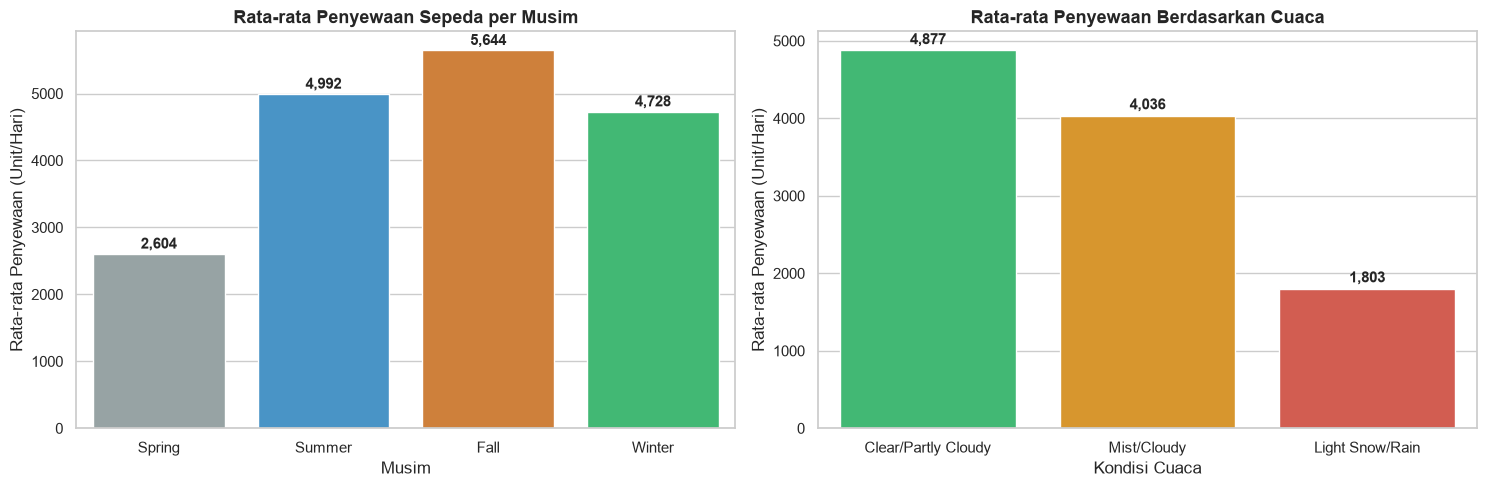

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Visualisasi Musim
season_mean = day_clean_df.groupby("season_label")["cnt"].mean().reindex(["Spring", "Summer", "Fall", "Winter"])
sns.barplot(
    x=season_mean.index,
    y=season_mean.values,
    hue=season_mean.index,
    palette=["#95a5a6", "#3498db", "#e67e22", "#2ecc71"],
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Rata-rata Penyewaan Sepeda per Musim", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata Penyewaan (Unit/Hari)")
for i, v in enumerate(season_mean.values):
    axes[0].text(i, v + 80, f"{v:,.0f}", ha="center", fontweight="bold")

# Visualisasi Kondisi Cuaca
weather_mean = day_clean_df.groupby("weather_label")["cnt"].mean().sort_values(ascending=False)
sns.barplot(
    x=weather_mean.index,
    y=weather_mean.values,
    hue=weather_mean.index,
    palette=["#2ecc71", "#f39c12", "#e74c3c"],
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Rata-rata Penyewaan Berdasarkan Cuaca", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Kondisi Cuaca")
axes[1].set_ylabel("Rata-rata Penyewaan (Unit/Hari)")
for i, v in enumerate(weather_mean.values):
    axes[1].text(i, v + 80, f"{v:,.0f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### Pertanyaan 2:

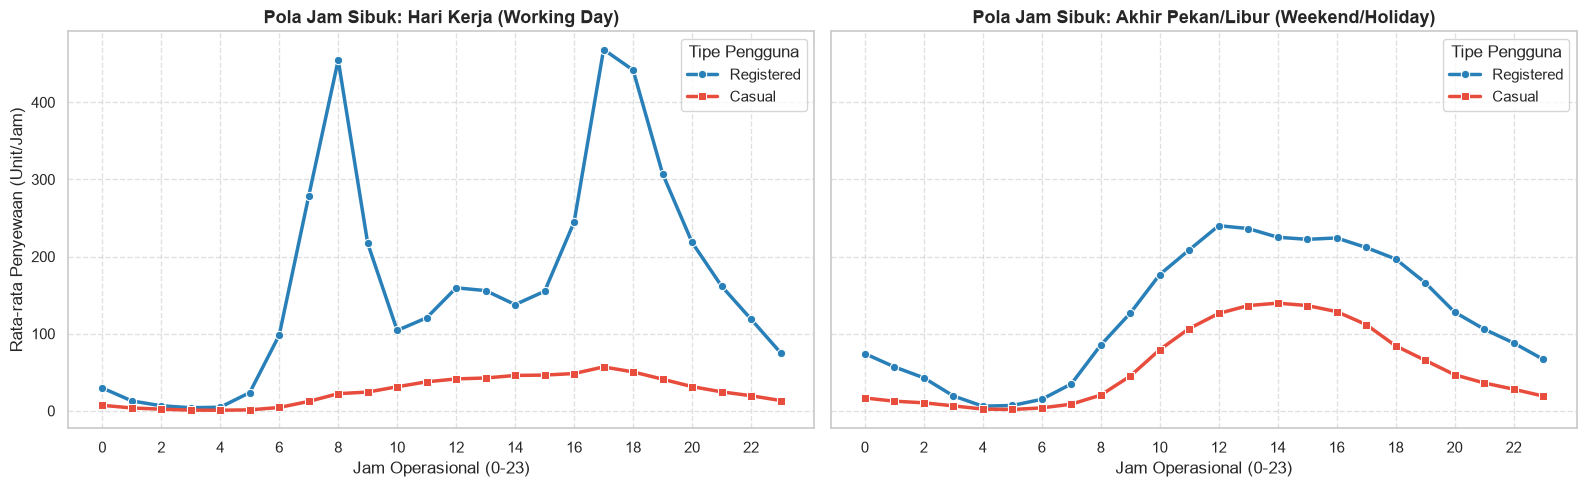

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
hourly_agg = hour_clean_df.groupby(["workingday_label", "hr"])[["casual", "registered"]].mean().reset_index()

# Subplot 1: Hari Kerja
working_df = hourly_agg[hourly_agg["workingday_label"] == "Working Day"]
sns.lineplot(data=working_df, x="hr", y="registered", ax=axes[0], label="Registered", color="#2980b9", linewidth=2.5, marker="o")
sns.lineplot(data=working_df, x="hr", y="casual", ax=axes[0], label="Casual", color="#e74c3c", linewidth=2.5, marker="s")
axes[0].set_title("Pola Jam Sibuk: Hari Kerja (Working Day)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Jam Operasional (0-23)")
axes[0].set_ylabel("Rata-rata Penyewaan (Unit/Jam)")
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend(title="Tipe Pengguna")

# Subplot 2: Hari Libur
weekend_df = hourly_agg[hourly_agg["workingday_label"] == "Weekend/Holiday"]
sns.lineplot(data=weekend_df, x="hr", y="registered", ax=axes[1], label="Registered", color="#2980b9", linewidth=2.5, marker="o")
sns.lineplot(data=weekend_df, x="hr", y="casual", ax=axes[1], label="Casual", color="#e74c3c", linewidth=2.5, marker="s")
axes[1].set_title("Pola Jam Sibuk: Akhir Pekan/Libur (Weekend/Holiday)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Jam Operasional (0-23)")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend(title="Tipe Pengguna")

plt.tight_layout()
plt.show()

### Pertanyaan 3:

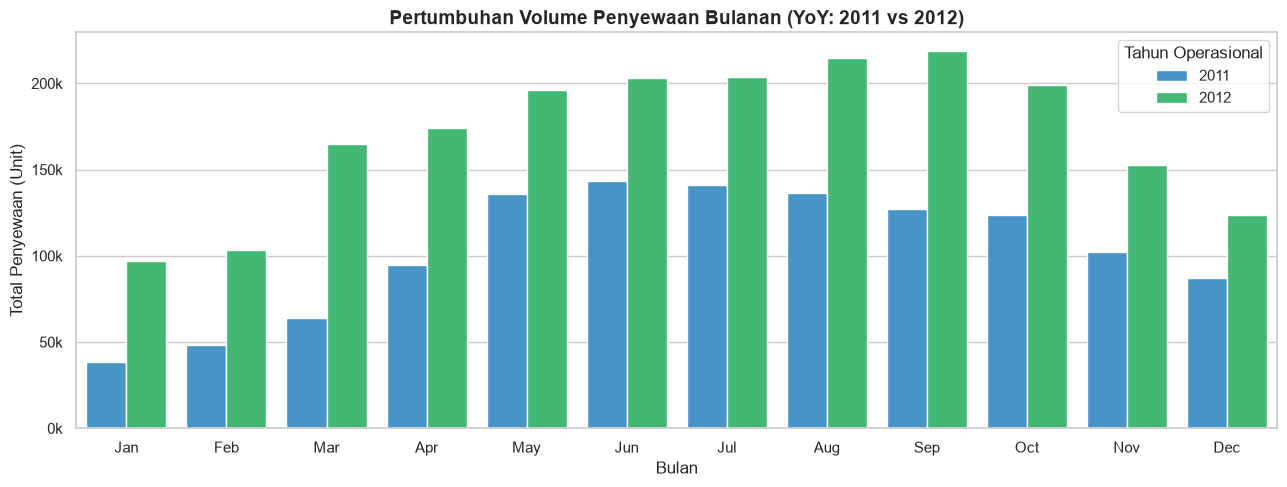

In [10]:
monthly_df = day_clean_df.groupby(["year_label", "month_label"], observed=False)["cnt"].sum().reset_index()

fig, ax = plt.subplots(figsize=(13, 5))
sns.barplot(
    data=monthly_df,
    x="month_label",
    y="cnt",
    hue="year_label",
    palette=["#3498db", "#2ecc71"],
    ax=ax
)
ax.set_title("Pertumbuhan Volume Penyewaan Bulanan (YoY: 2011 vs 2012)", fontsize=14, fontweight="bold")
ax.set_xlabel("Bulan")
ax.set_ylabel("Total Penyewaan (Unit)")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x*1e-3):,}k"))
ax.legend(title="Tahun Operasional")
plt.tight_layout()
plt.show()

**Insight:**
- **Pertanyaan 1:** Grafik menunjukkan preferensi pengguna yang sangat kuat terhadap iklim hangat dan cuaca cerah. Musim Gugur (*Fall*) menghasilkan rata-rata sewa harian tertinggi (5.644 unit), sedangkan pada kondisi cuaca *Light Snow/Rain* rata-rata penyewaan anjlok menjadi hanya 1.803 unit/hari (-63,02%).
- **Pertanyaan 2:** Terdapat dikotomi pola penggunaan yang sangat tegas: pada hari kerja, lonjakan tajam terjadi pada jam berangkat kerja (pukul 08:00) dan pulang kerja (pukul 17:00–18:00) oleh pengguna *registered*, sedangkan pada akhir pekan/libur kurva berubah menjadi pola rekreasi landai dengan puncak di siang-sore hari (pukul 12:00–16:00).
- **Pertanyaan 3:** Volume penyewaan pada tahun 2012 mengalami pertumbuhan konsisten di seluruh 12 bulan dibandingkan tahun 2011, dengan persentase kenaikan tertinggi pada kuartal pertama (Januari–Maret tumbuh >110% YoY) dan volume puncak pada September 2012 (218.573 unit).

## Analisis Lanjutan (Opsional)

=== ANALISIS LANJUTAN: MANUAL CLUSTERING VIA BINNING ===

,rata_rata_sewa,total_sewa,rata_rata_casual,rata_rata_registered
time_cluster,,,,
Evening Commute (16:00-19:59),377.63,1101169,64.49,313.14
Midday Activity (10:00-15:59),230.19,1005711,66.19,164.00
Morning Commute (06:00-09:59),216.70,629742,16.96,199.75
Night / Off-Peak (20:00-05:59),77.36,556057,13.01,64.35


,frekuensi_hari,rata_rata_harian,total_penyewaan
temp_comfort_cluster,,,
Cold (<15°C),221,2833.32,626163
Comfortable (15-25°C),268,4863.95,1303539
Warm/Hot (>25°C),242,5632.14,1362977


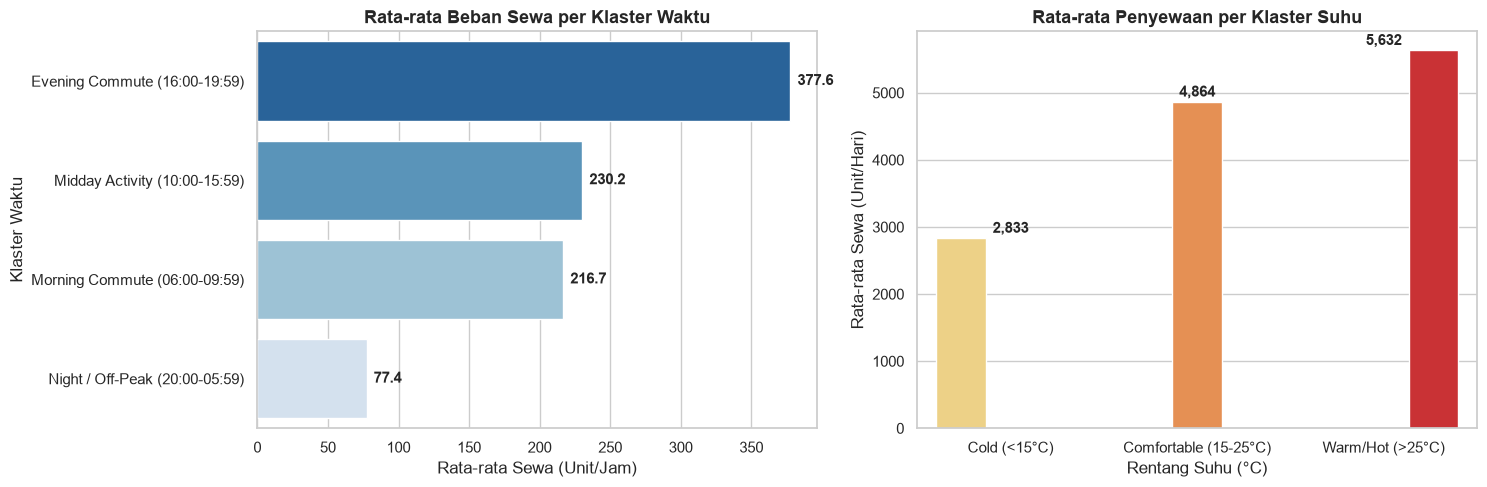

In [11]:
print("=== ANALISIS LANJUTAN: MANUAL CLUSTERING VIA BINNING ===")

# 1. Time-of-Day Clustering (Klaster Jam Operasional)
def categorize_time_cluster(hour: int) -> str:
    if 6 <= hour <= 9:
        return "Morning Commute (06:00-09:59)"
    elif 10 <= hour <= 15:
        return "Midday Activity (10:00-15:59)"
    elif 16 <= hour <= 19:
        return "Evening Commute (16:00-19:59)"
    else:
        return "Night / Off-Peak (20:00-05:59)"

hour_clean_df["time_cluster"] = hour_clean_df["hr"].apply(categorize_time_cluster)

time_cluster_agg = hour_clean_df.groupby("time_cluster")[["casual", "registered", "cnt"]].agg(
    rata_rata_sewa=("cnt", "mean"),
    total_sewa=("cnt", "sum"),
    rata_rata_casual=("casual", "mean"),
    rata_rata_registered=("registered", "mean")
).sort_values(by="rata_rata_sewa", ascending=False)
display(time_cluster_agg.round(2))

# 2. Temperature Comfort Clustering (Klaster Suhu Nyaman)
temp_bins = [0, 15, 25, 45]
temp_labels = ["Cold (<15°C)", "Comfortable (15-25°C)", "Warm/Hot (>25°C)"]
day_clean_df["temp_comfort_cluster"] = pd.cut(day_clean_df["temp_c"], bins=temp_bins, labels=temp_labels)

temp_cluster_agg = day_clean_df.groupby("temp_comfort_cluster", observed=False)["cnt"].agg(
    frekuensi_hari="count",
    rata_rata_harian="mean",
    total_penyewaan="sum"
)
display(temp_cluster_agg.round(2))

# Perbarui dashboard/main_data.csv agar kolom klaster tersimpan
hour_clean_df.to_csv(os.path.join("dashboard", "main_data.csv"), index=False)

# Visualisasi Hasil Manual Clustering
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

time_cluster_mean = hour_clean_df.groupby("time_cluster")["cnt"].mean().sort_values(ascending=False)
sns.barplot(
    x=time_cluster_mean.values,
    y=time_cluster_mean.index,
    hue=time_cluster_mean.index,
    palette="Blues_r",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Rata-rata Beban Sewa per Klaster Waktu", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Rata-rata Sewa (Unit/Jam)")
axes[0].set_ylabel("Klaster Waktu")
for i, v in enumerate(time_cluster_mean.values):
    axes[0].text(v + 5, i, f"{v:,.1f}", va="center", fontweight="bold")

temp_cluster_mean = day_clean_df.groupby("temp_comfort_cluster", observed=False)["cnt"].mean()
sns.barplot(
    x=temp_cluster_mean.index,
    y=temp_cluster_mean.values,
    hue=temp_cluster_mean.index,
    palette="YlOrRd",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Rata-rata Penyewaan per Klaster Suhu", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Rentang Suhu (°C)")
axes[1].set_ylabel("Rata-rata Sewa (Unit/Hari)")
for i, v in enumerate(temp_cluster_mean.values):
    axes[1].text(i, v + 80, f"{v:,.0f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

**Insight:**
- Segmentasi waktu (*Time-of-Day Clustering*) membuktikan bahwa klaster **Evening Commute (16:00–19:59)** memikul intensitas transaksi tertinggi (**377,63 unit/jam**, total 1.101.169 unit), diikuti **Midday Activity (10:00–15:59)** (**230,19 unit/jam**) dan **Morning Commute (06:00–09:59)** (**216,70 unit/jam**).
- Segmentasi temperatur (*Temperature Comfort Clustering*) menunjukkan bahwa hari bersuhu **Warm/Hot (>25°C)** dan **Comfortable (15–25°C)** menghasilkan rata-rata sewa harian tertinggi (**5.632,14** dan **4.863,95 unit/hari**), hampir dua kali lipat dibandingkan hari bersuhu **Cold (<15°C)** (**2.833,32 unit/hari**).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Perubahan musim dan kondisi cuaca sangat memengaruhi penyewaan sepeda harian selama periode 2011–2012. Musim Gugur (*Fall*) mencatat rata-rata sewa tertinggi (**5.644,30 unit/hari**) dan cuaca cerah (*Clear/Partly Cloudy*) mencapai **4.876,79 unit/hari**, sedangkan penurunan paling drastis terjadi pada kondisi cuaca hujan/salju ringan (*Light Snow/Rain*) yang merosot sebesar **63,02%** menjadi rata-rata **1.803,29 unit/hari**.
- **Conclusion pertanyaan 2:** Pengguna terdaftar (*registered*) mendominasi hari kerja (*workingday = 1*) dengan pola bimodal tajam pada jam komuter berangkat kerja (**pukul 08:00**, rata-rata 477,01 unit/jam) dan pulang kerja (**pukul 17:00–18:00**, rata-rata 525,29 dan 492,23 unit/jam). Sebaliknya, pada akhir pekan/libur (*workingday = 0*), kurva penyewaan berpola unimodal di siang-sore hari (**pukul 12:00–16:00**) yang didorong oleh lonjakan aktivitas rekreasi pengguna kasual (*casual*).
- **Conclusion pertanyaan 3:** Jumlah penyewaan sepeda mengalami pertumbuhan tahunan (*Year-over-Year*) sebesar **64,88%** dari **1.243.103 unit** (2011) menjadi **2.049.576 unit** (2012) dengan peningkatan positif di seluruh 12 bulan (pertumbuhan tertinggi pada Maret sebesar **+157,44% YoY**), di mana segmen *registered* memberikan kontribusi terbesar sejumlah **81,17%** (2.672.662 unit) dibandingkan *casual* sebesar **18,83%** (620.017 unit).

**Rekomendasi Action Item:**
- **Dynamic Fleet Rebalancing pada Jam Komuter:** Menjadwalkan truk operasional redistribusi sepeda ke stasiun area pemukiman sebelum pukul 07:30 dan ke stasiun kawasan perkantoran/transit sebelum pukul 16:30 pada hari kerja guna mencegah kekosongan unit saat beban puncak klaster *Morning & Evening Commute*.
- **Program Bundling Akhir Pekan & Konversi Member:** Meluncurkan paket promosi *Weekend Leisure Pass* serta diskon pendaftaran member bagi pengguna *casual* yang menyewa sepeda pada rentang pukul 10:00–16:00 di akhir pekan/hari libur untuk meningkatkan akuisisi pelanggan *registered*.
- **Manajemen Armada & Maintenance Berbasis Cuaca/Musim:** Mengoptimalkan jadwal perawatan berkala (*preventive maintenance*) armada pada musim *Spring* atau saat prakiraan cuaca menunjukkan hujan/salju (*Light Snow/Rain*) dan suhu dingin (<15°C) ketika permintaan harian turun di bawah 2.850 unit.